# Online Retail Customer Segmentation


## Objective

Use recency, frequency, and monetary value (RFM) to describe observed purchasing behavior and identify interpretable customer groups with K-Means.

## Dataset

The UCI Online Retail dataset contains transactions for a UK-based non-store retailer from December 2010 to December 2011. Download instructions are in `data/README.md`; the raw workbook is intentionally not committed.

## Method

Cancelled invoices, invalid quantities/prices, duplicates, and rows without customer identifiers are removed. RFM features are log-transformed, standardized, clustered, and visualized with PCA. Cluster choice combines inertia, silhouette score, Davies–Bouldin score, stability of interpretation, and business usefulness.


## Objectives
The specific objectives of this project are-
* To understand spending behaviour of customers of an online retail firm through exploratory analysis.
* To optimally segment the customer in term of purchasing behavioural features (Recency, Frequency and Monetary) through unsupervised learning.
* To interpret each customer segment in terms of activeness, transactional frequency and purchase value. 

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import ML libraries
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Clean plotting style
sns.set_style("whitegrid")

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## **1. Data Understanding and Loading**
The dataset consists of online transactions for a UK-based registered non-store online retail firm from 01/12/2010 and 09/12/2011. The firm mainly sells items like unique occasion gifts to its customers who are mostly wholesalers. The dataset has the following attributes.
* InvoiceNo - invoice number
* StockCode - product code
* Description - product description
* Quantity - quantity sold
* InvoiceDate - transaction date
* UnitPrice - price of product per unit (£)
* CustomerID - unique customer ID
* Country - country of customer residence

The data has a total of 541909 transactional records for the above 8 attributes of which two are numeric, one is datetime type and rest are string or categorical types.

In [ ]:
# Load the manually downloaded UCI workbook from a repository-relative path.
from pathlib import Path

candidate_paths = [Path("data/online-retail.xlsx"), Path("../data/online-retail.xlsx")]
retail_path = next((path for path in candidate_paths if path.exists()), None)
if retail_path is None:
    raise FileNotFoundError("Download Online Retail.xlsx as data/online-retail.xlsx; see data/README.md")

df = pd.read_excel(retail_path)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


## **2. Dataset Preprocessing**

### **2.1 Initial Data Quality Check**

In [3]:
# Missing values
missing_values = df.isnull().sum()

# Duplicate rows
duplicate_count = df.duplicated().sum()

# Cancellation invoices
cancelled_orders = df["InvoiceNo"].astype(str).str.startswith("C").sum()

# Invalid quantities and prices
negative_quantity = (df["Quantity"] < 0).sum()
zero_quantity = (df["Quantity"] == 0).sum()
negative_price = (df["UnitPrice"] < 0).sum()
zero_price = (df["UnitPrice"] == 0).sum()

# Display checks
quality_check = pd.DataFrame({
    "Check": [
        "Missing CustomerID",
        "Missing Description",
        "Duplicate Rows",
        "Cancelled Orders",
        "Negative Quantity",
        "Zero Quantity",
        "Negative UnitPrice",
        "Zero UnitPrice"
    ],
    "Count": [
        missing_values.get("CustomerID", 0),
        missing_values.get("Description", 0),
        duplicate_count,
        cancelled_orders,
        negative_quantity,
        zero_quantity,
        negative_price,
        zero_price
    ]
})

display(quality_check)

,Check,Count
0,Missing CustomerID,135080
1,Missing Description,1454
2,Duplicate Rows,5268
3,Cancelled Orders,9288
4,Negative Quantity,10624
5,Zero Quantity,0
6,Negative UnitPrice,2
7,Zero UnitPrice,2515


The initial investigation show many missing customer IDs and descriptions, some duplicate rows, cancelled orders, negative quantity and a few negative as well zero unit price. 

### **2.2 Remove Invalid and Incomplete Records**

In [4]:
# Create cleaned copy
df_clean = df.copy()

# Remove rows without CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only valid quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (541909, 8)
Cleaned shape: (392692, 8)


The dataset is cleaned in following way.
* Missing customer ID and descrioptions - listwise removed
* Duplicates - dropped by keeping the first occurence
* Cancelled invoices - removed listwise
* Invalid quantities and unit prices - remove listwise

This results net 392692 records for further analysis.

### **2.3 Fix Data Types**

In [5]:
# Convert customer ID to string
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int).astype(str)

# Convert invoice date
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Check updated structure
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[ns]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  object        
 7   Country      392692 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 27.0+ MB


* Customer ID - converted to string
* Invoice date - converted to datetime

### **2.4 Create Sales Value**

In [6]:
# Calculate total transaction value
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Preview cleaned data
display(df_clean.head())

# Check total sales range
print("\nMinimum TotalPrice:", df_clean["TotalPrice"].min())
print("Maximum TotalPrice:", df_clean["TotalPrice"].max())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



Minimum TotalPrice: 0.001
Maximum TotalPrice: 168469.6


* Total sales value = Quantity sold * Unit Price
* Min and Max Total Price are computed

### **2.5 Pre-processed Data Quality Check**

In [7]:
# Recheck missing values and invalid records
cleaning_check = pd.DataFrame({
    "Check": [
        "Missing CustomerID",
        "Missing Description",
        "Duplicate Rows",
        "Cancelled Orders",
        "Negative Quantity",
        "Zero Quantity",
        "Negative UnitPrice",
        "Zero UnitPrice"
    ],
    "Count": [
        df_clean["CustomerID"].isnull().sum(),
        df_clean["Description"].isnull().sum(),
        df_clean.duplicated().sum(),
        df_clean["InvoiceNo"].astype(str).str.startswith("C").sum(),
        (df_clean["Quantity"] < 0).sum(),
        (df_clean["Quantity"] == 0).sum(),
        (df_clean["UnitPrice"] < 0).sum(),
        (df_clean["UnitPrice"] == 0).sum()
    ]
})

display(cleaning_check)

print("Final cleaned shape:", df_clean.shape)
print("Date range:", df_clean["InvoiceDate"].min(), "to", df_clean["InvoiceDate"].max())
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Unique invoices:", df_clean["InvoiceNo"].nunique())

,Check,Count
0,Missing CustomerID,0
1,Missing Description,0
2,Duplicate Rows,0
3,Cancelled Orders,0
4,Negative Quantity,0
5,Zero Quantity,0
6,Negative UnitPrice,0
7,Zero UnitPrice,0


Final cleaned shape: (392692, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique customers: 4338
Unique invoices: 18532


## **3. Exploratory Data Analysis**

### **3.1 Revenue Feature**

In [8]:
# Create revenue column
df_clean["TotalPrice"] = (
    df_clean["Quantity"] *
    df_clean["UnitPrice"]
)

# Check revenue summary
revenue_summary = df_clean["TotalPrice"].describe()

display(revenue_summary)
display(df_clean.head())

,TotalPrice
count,392692.000000
mean,22.631500
std,311.099224
min,0.001000
25%,4.950000
50%,12.450000
75%,19.800000
max,168469.600000


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Average total price is about £22.63 with a very high standard deviation of £311.09 indicating its high range.

### **3.2 Country Distribution**

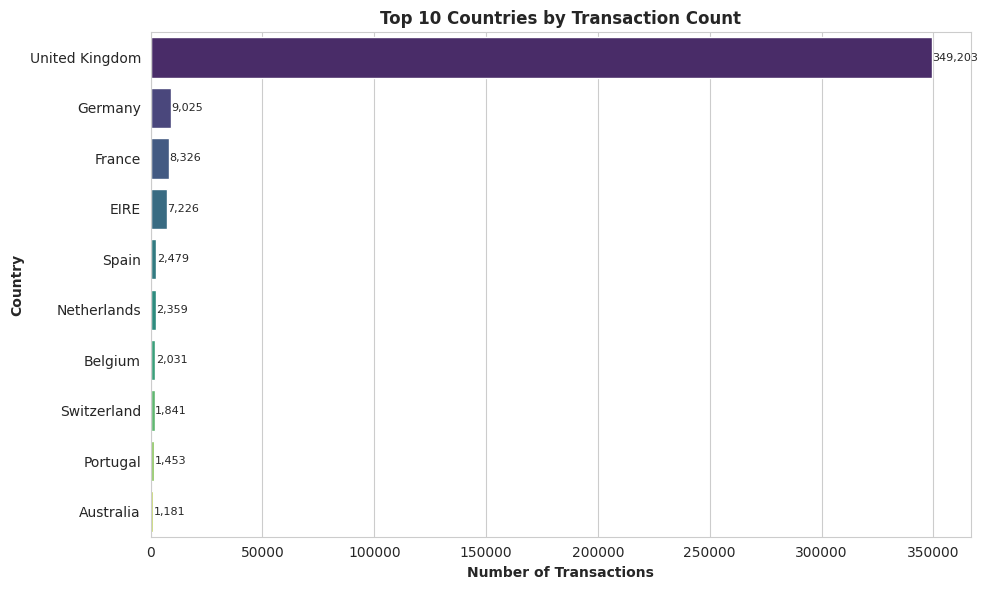

In [9]:
# Top countries by transaction count
top_countries = (
    df_clean["Country"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    palette="viridis"
)

for i, value in enumerate(top_countries.values):
    ax.text(value + 200, i, f"{value:,}", va="center", fontsize=8)

plt.title("Top 10 Countries by Transaction Count", fontsize=12, fontweight="bold")
plt.xlabel("Number of Transactions", fontsize=10, fontweight="bold")
plt.ylabel("Country", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

Most transactions are observed from UK, indicating the UK-based mostly sold to its homeland customers.

### **3.3 Monthly Revenue Trend**

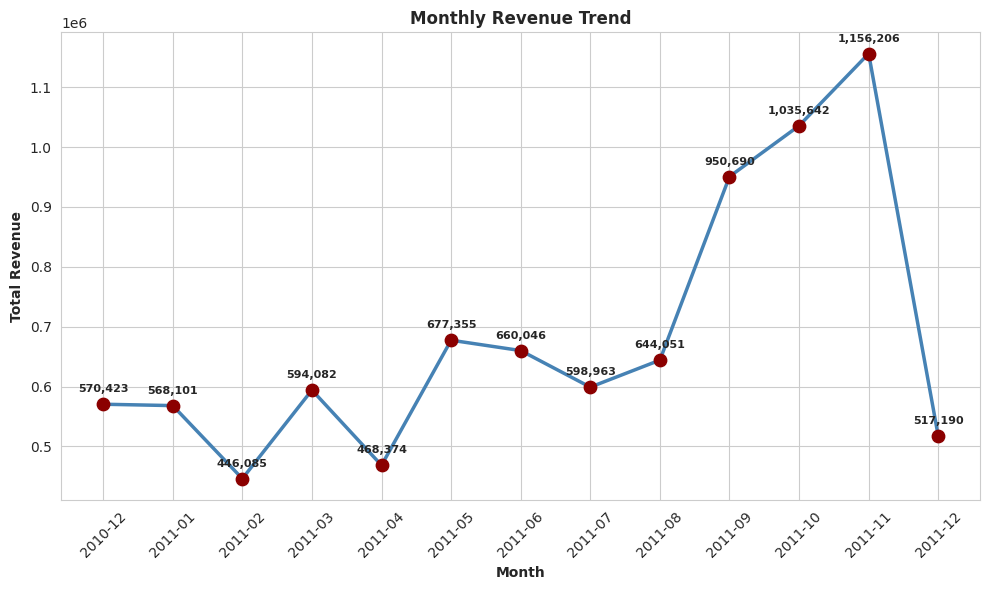

In [10]:
# Create month column
df_clean["YearMonth"] = (df_clean["InvoiceDate"].dt.to_period("M").astype(str))

# Monthly revenue
monthly_revenue = (df_clean.groupby("YearMonth")["TotalPrice"].sum().reset_index())
plt.figure(figsize=(10, 6))

# Line plot
ax = sns.lineplot(data=monthly_revenue, x="YearMonth", y="TotalPrice",
                  linewidth=2.5, color="steelblue")

# Scatter markers with different color
plt.scatter(monthly_revenue["YearMonth"], monthly_revenue["TotalPrice"],
            color="darkred", s=80, zorder=3)

# Add data labels
for i, row in monthly_revenue.iterrows():
    ax.text(i, row["TotalPrice"] + 20000, f"{row['TotalPrice']:,.0f}",
            ha="center", fontsize=8, fontweight="bold")

plt.title("Monthly Revenue Trend", fontsize=12, fontweight="bold")
plt.xlabel("Month", fontsize=10, fontweight="bold")
plt.ylabel("Total Revenue", fontsize=10, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Revenue trend shows total revenue lies mostly in £0.5-0.7M over the entire period with a sudden spike observed between September to November of 2011 with revenue around £1-1.2M indicating high demand for some event.

### **3.4 Top Products by Quantity Sold**

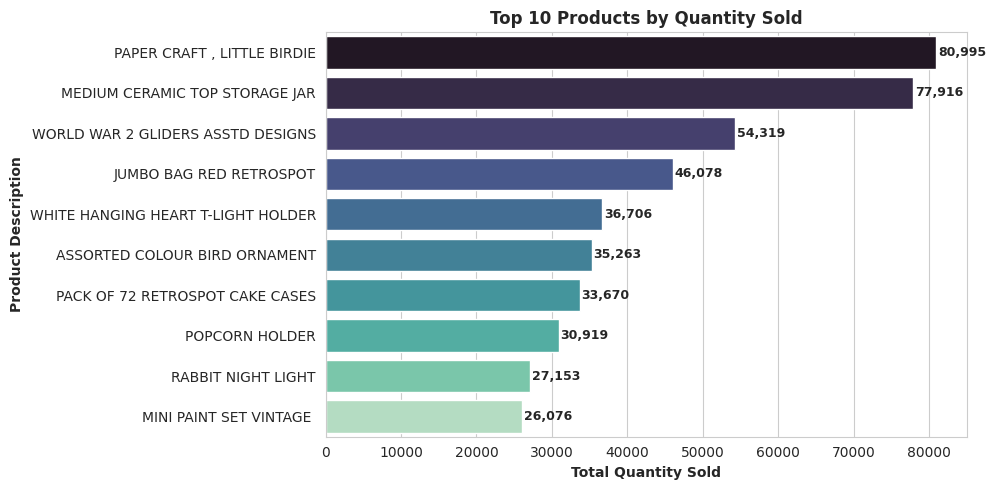

In [11]:
# Top products by total quantity
top_products = (df_clean.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10).reset_index())
plt.figure(figsize=(10, 5))

ax = sns.barplot(data=top_products, x="Quantity", y="Description", palette="mako")
for i, value in enumerate(top_products["Quantity"]):
    ax.text(value + 200, i, f"{value:,}", va="center", fontsize=9, fontweight="bold")

plt.title("Top 10 Products by Quantity Sold", fontsize=12, fontweight="bold")

plt.xlabel("Total Quantity Sold", fontsize=10, fontweight="bold")
plt.ylabel("Product Description", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

Among the top sold products, paper crafts and medium storage jars are most common with a moderate demand for world war designs, jumbo bags while others were infrequently sold.

### **3.5 Customer Spending Distribution**

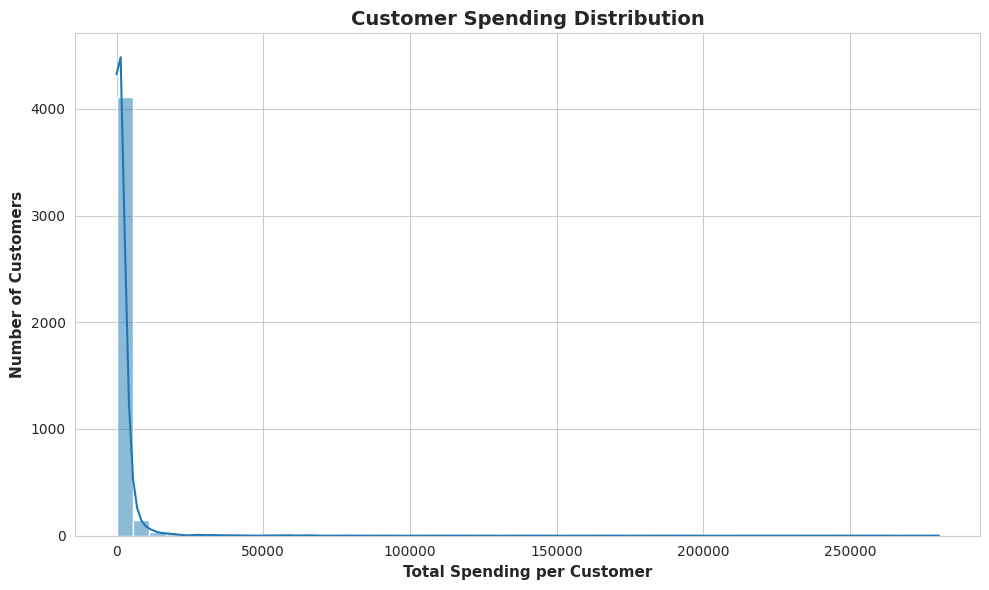

In [12]:
# Total spending per customer
customer_spending = (
    df_clean
    .groupby("CustomerID")["TotalPrice"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.histplot(
    customer_spending["TotalPrice"],
    bins=50,
    kde=True
)

plt.title("Customer Spending Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Total Spending per Customer", fontsize=11, fontweight="bold")
plt.ylabel("Number of Customers", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

Customer spending distribution is heavily left-skewed with most customer spending about £0-5000 in the whole period while there are very few rich customers who spend over this range.

### **3.6 Customer Spending Summary**

In [13]:
# Customer spending statistics
spending_summary = customer_spending["TotalPrice"].describe()

# Top spending customers
top_customers = (
    customer_spending
    .sort_values("TotalPrice", ascending=False)
    .head(10)
)

display(spending_summary)
display(top_customers)

,TotalPrice
count,4338.000000
mean,2048.688081
std,8985.230220
min,3.750000
25%,306.482500
50%,668.570000
75%,1660.597500
max,280206.020000


,CustomerID,TotalPrice
1689,14646,280206.02
4201,18102,259657.30
3728,17450,194390.79
3008,16446,168472.50
1879,14911,143711.17
55,12415,124914.53
1333,14156,117210.08
3771,17511,91062.38
2702,16029,80850.84
0,12346,77183.60


The average total spending is around £2048.69 with a very high SD of £8985 indicating a wide range of spending. Among top 10 customers by spending a wide variation is observed with about £280206 spending by the first customer while only £77183 spending by 10th customer by rank.

## **4. Feature Engineering**

### **4.1 RFM Feature Generation**

In [14]:
# Create reference date
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Snapshot date:", snapshot_date)

Snapshot date: 2011-12-10 12:50:00


In [15]:
# Create RFM features
rfm = (
    df_clean
    .groupby("CustomerID")
    .agg({
        "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
        "InvoiceNo": "nunique",
        "TotalPrice": "sum"
    })
)

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Reset index
rfm = rfm.reset_index()

display(rfm.head())

print("RFM shape:", rfm.shape)

# Recency: days since the customer's latest valid purchase.
# Frequency: number of distinct valid invoices.
# Monetary: total revenue from valid retained purchases.


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


RFM shape: (4338, 4)


The following features were calculated to describe customer behaviour.
* Recency - days since last purchase with latest invoice date
* Frequency - number of orders by customer
* Monetary - total monetary value of spending by customer

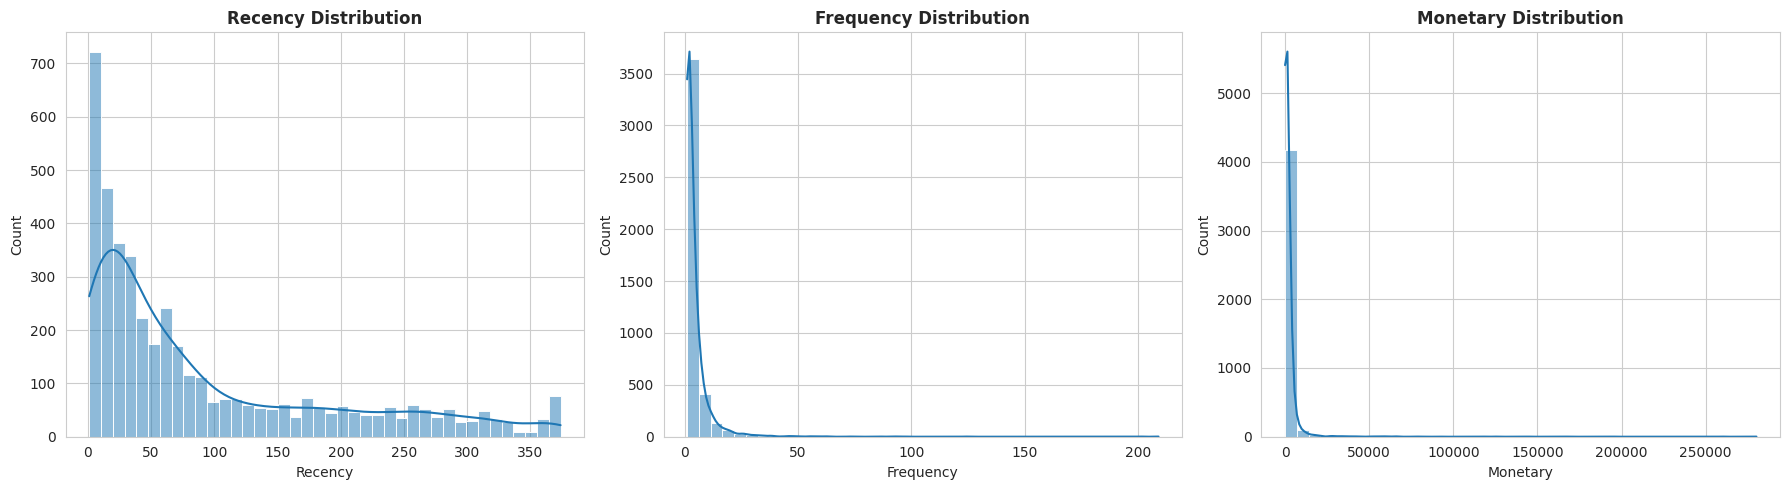

In [16]:
# Plot distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
sns.histplot(rfm["Recency"], bins=40, kde=True, ax=axes[0])

axes[0].set_title("Recency Distribution", fontsize=12, fontweight="bold")

# Frequency distribution
sns.histplot(rfm["Frequency"], bins=40, kde=True, ax=axes[1])

axes[1].set_title("Frequency Distribution", fontsize=12, fontweight="bold")

# Monetary distribution
sns.histplot(rfm["Monetary"], bins=40, kde=True, ax=axes[2])

axes[2].set_title("Monetary Distribution", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

The distributions of above features show all are positively skewed with very high skewness observed for frequency and monetrary distributions than recency distribution.

### **4.2 Log Transformation**

In [17]:
# Create transformed copy
rfm_log = rfm.copy()

# Apply log transformation
rfm_log["Recency"] = np.log1p(rfm_log["Recency"])

rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])

rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

display(rfm_log.head())

,CustomerID,Recency,Frequency,Monetary
0,12346,5.789960,0.693147,11.253955
1,12347,1.098612,2.079442,8.368925
2,12348,4.330733,1.609438,7.494564
3,12349,2.995732,0.693147,7.472245
4,12350,5.739793,0.693147,5.815324


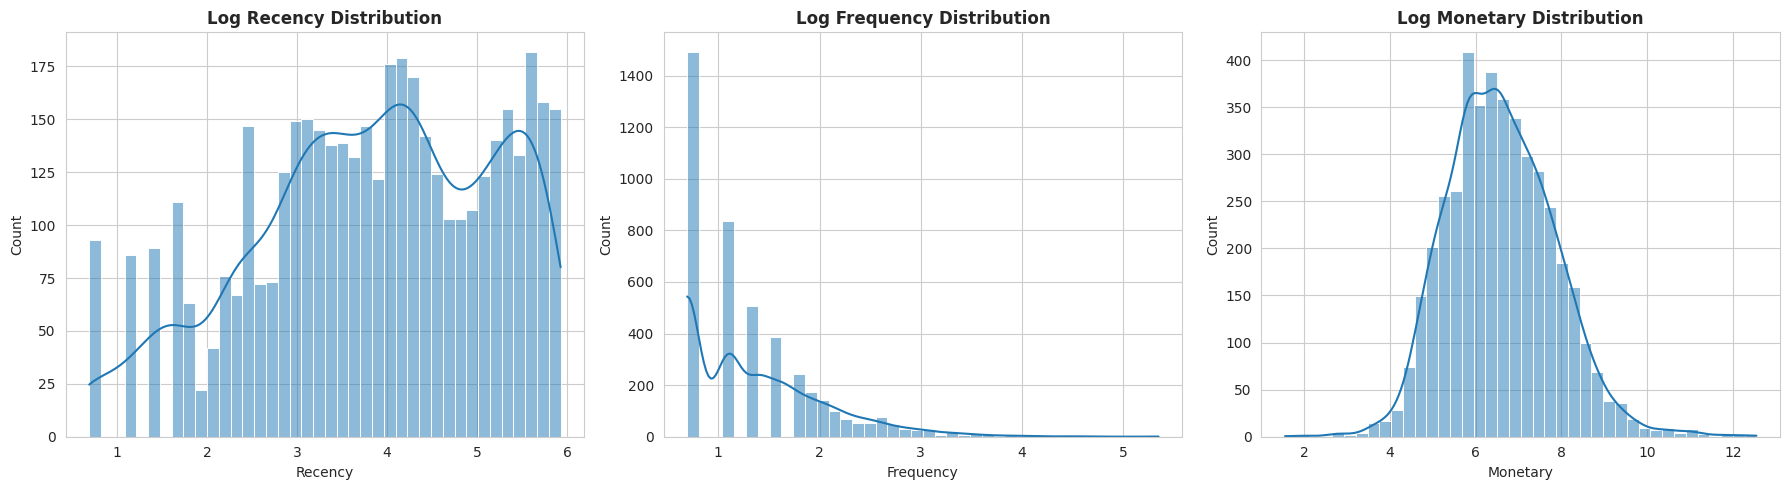

In [18]:
# Plot transformed distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Log recency distribution
sns.histplot(rfm_log["Recency"], bins=40, kde=True, ax=axes[0])

axes[0].set_title("Log Recency Distribution", fontsize=12, fontweight="bold")

# Log frequency distribution
sns.histplot(rfm_log["Frequency"], bins=40, kde=True, ax=axes[1])

axes[1].set_title("Log Frequency Distribution", fontsize=12, fontweight="bold")

# Log monetary distribution
sns.histplot(rfm_log["Monetary"], bins=40, kde=True, ax=axes[2])

axes[2].set_title("Log Monetary Distribution", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

Log transformation of the features is performed reduce high skewness which can affect fitting of the unsupervised models. After log transformation Recency is slightly negatively skewed, while frequency remains positively skewed, however, monetary distribution has become approximately normally distributed.

### **4.3 Feature Scaling**

In [19]:
# Select transformed RFM features
rfm_features = rfm_log[["Recency", "Frequency", "Monetary"]]

# Preview selected features
display(rfm_features.head())
display(rfm_features.describe())

,Recency,Frequency,Monetary
0,5.789960,0.693147,11.253955
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,3.830734,1.345582,6.588562
std,1.340261,0.683104,1.258438
min,0.693147,0.693147,1.558145
25%,2.944439,0.693147,5.728418
50%,3.951244,1.098612,6.506636
75%,4.962845,1.791759,7.415535
max,5.926926,5.347108,12.543284


In [20]:
# Import scaler
from sklearn.preprocessing import StandardScaler

# Scale RFM features
scaler = StandardScaler()
rfm_scaled_array = scaler.fit_transform(rfm_features)

# Convert scaled array to dataframe
rfm_scaled = pd.DataFrame(rfm_scaled_array, columns=rfm_features.columns)

# Preview scaled data
display(rfm_scaled.head())
display(rfm_scaled.describe())

,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.707716
1,-2.038734,1.074425,1.414903
2,0.373104,0.386304,0.720024
3,-0.623086,-0.955214,0.702287
4,1.424558,-0.955214,-0.614514


,Recency,Frequency,Monetary
count,4.338000e+03,4.338000e+03,4.338000e+03
mean,-9.172520e-17,-7.206980e-17,-3.669008e-16
std,1.000115e+00,1.000115e+00,1.000115e+00
min,-2.341296e+00,-9.552143e-01,-3.997811e+00
25%,-6.613615e-01,-9.552143e-01,-6.835802e-01
50%,8.992557e-02,-3.615828e-01,-6.510929e-02
75%,8.447915e-01,6.532370e-01,6.572178e-01
max,1.564198e+00,5.858535e+00,4.732381e+00


The features are also standardised for better fitting of unsupervised model and as seen from above statistic each feature has about zero mean and unit standard deviation.

## **5. Clustering**

### **5.1 Elbow Method**

In [21]:
# Calculate inertia values
inertia_scores = []
cluster_range = range(1, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia_scores.append(kmeans.inertia_)

# Store results
elbow_df = pd.DataFrame({
    "k": list(cluster_range),
    "Inertia": inertia_scores
})

display(elbow_df)

,k,Inertia
0,1,13014.000000
1,2,6483.589425
2,3,4869.488629
3,4,3939.049382
4,5,3296.708708
5,6,2855.764068
6,7,2548.820245
7,8,2336.341054
8,9,2156.005673
9,10,2005.746236


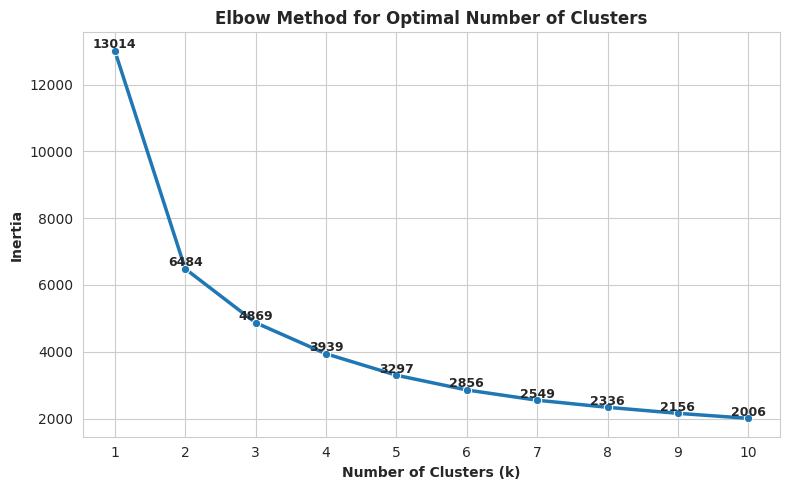

In [22]:
# Plot elbow method
plt.figure(figsize=(8, 5))

ax = sns.lineplot(data=elbow_df, x="k", y="Inertia", marker="o", linewidth=2.5)

# Add data labels
for i, row in elbow_df.iterrows():
    ax.text(row["k"], row["Inertia"] + 80, f"{row['Inertia']:.0f}",
            ha="center", fontsize=9, fontweight="bold")

plt.title("Elbow Method for Optimal Number of Clusters", fontsize=12, fontweight="bold")
plt.xlabel("Number of Clusters (k)", fontsize=10, fontweight="bold")
plt.ylabel("Inertia", fontsize=10, fontweight="bold")
plt.xticks(list(cluster_range))

plt.tight_layout()
plt.show()

The k-means clustering through elbow method of the three scaled features show elbow around k=4 as over this the rate of decrease of inertia has not changed significantly.

### **5.2 Final k Selection**

### Cluster evaluation

Inertia always decreases as more clusters are added, so it is considered alongside silhouette score (higher is better) and Davies–Bouldin score (lower is better). The quantitative metrics favor a simpler two-cluster partition, while the retained four-cluster solution provides more useful distinctions in recent, occasional, regular, and high-value observed behavior. This is an explicit interpretability trade-off, not evidence that four clusters are objectively correct.


In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

cluster_evaluation_rows = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = candidate.fit_predict(rfm_scaled)
    cluster_evaluation_rows.append({
        "k": k,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(rfm_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(rfm_scaled, labels),
    })

cluster_evaluation = pd.DataFrame(cluster_evaluation_rows)
display(cluster_evaluation.round(4))


   k    Inertia  Silhouette  Davies-Bouldin
0  2  6483.5894      0.4328          0.8925
1  3  4869.4886      0.3365          1.0483
2  4  3939.0494      0.3375          1.0086
3  5  3296.7087      0.3162          0.9878
4  6  2855.7641      0.3124          1.0210
5  7  2548.8202      0.3092          0.9823
6  8  2336.3411      0.3033          0.9892


In [23]:
# Fit final K-Means model
final_k = 4

kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)

rfm["Cluster"] = kmeans_final.fit_predict(rfm_scaled)
rfm_log["Cluster"] = rfm["Cluster"]

# Preview clustered data
display(rfm.head())
display(rfm["Cluster"].value_counts().sort_index())

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1


,count
Cluster,
0,713
1,1622
2,837
3,1166


In [ ]:
# Robust final segment table using medians on the original RFM scale
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
    )
    .round(2)
)
display(cluster_profile)


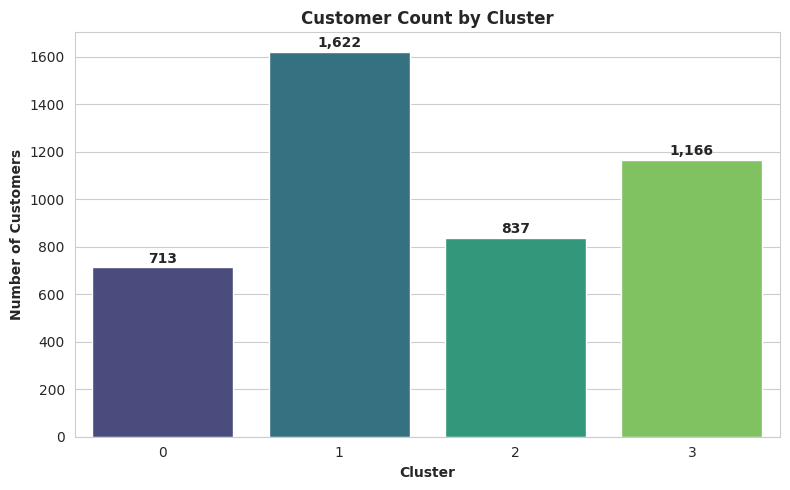

In [25]:
# Cluster sizes
cluster_sizes = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_sizes.columns = ["Cluster", "CustomerCount"]

plt.figure(figsize=(8, 5))

ax = sns.barplot(data=cluster_sizes, x="Cluster", y="CustomerCount", palette="viridis")

# Add data labels
for i, row in cluster_sizes.iterrows():
    ax.text(i, row["CustomerCount"] + 20, f"{row['CustomerCount']:,}",
            ha="center", fontsize=10, fontweight="bold")

plt.title("Customer Count by Cluster", fontsize=12, fontweight="bold")
plt.xlabel("Cluster", fontsize=10, fontweight="bold")
plt.ylabel("Number of Customers", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

In [26]:
# Define cluster labels
segment_map = {
    0: "High-Value Loyal Customers",
    1: "Inactive / Churn-Risk Customers",
    2: "New or Occasional Customers",
    3: "Regular Mid-Value Customers"
}

# Add segment names
rfm["Segment"] = rfm["Cluster"].map(segment_map)

# Preview final RFM segments
display(rfm.head())

# Segment summary
segment_summary = (
    rfm
    .groupby("Segment")
    .agg({
        "CustomerID": "count",
        "Recency": "mean",
        "Frequency": "mean",
        "Monetary": "mean"
    })
    .rename(columns={"CustomerID": "CustomerCount"})
    .round(2)
    .sort_values("Monetary", ascending=False)
)

display(segment_summary)

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Regular Mid-Value Customers
1,12347,2,7,4310.00,0,High-Value Loyal Customers
2,12348,75,4,1797.24,3,Regular Mid-Value Customers
3,12349,19,1,1757.55,2,New or Occasional Customers
4,12350,310,1,334.40,1,Inactive / Churn-Risk Customers


,CustomerCount,Recency,Frequency,Monetary
Segment,,,,
High-Value Loyal Customers,713,12.17,13.75,8088.02
Regular Mid-Value Customers,1166,71.64,4.08,1801.78
New or Occasional Customers,837,17.70,2.19,557.32
Inactive / Churn-Risk Customers,1622,181.51,1.32,341.00


The four-cluster solution retains the original, interpretable RFM structure. Median profiles are used because purchase frequency and monetary value remain heavy-tailed. Cluster 0 has the strongest observed value and most recent activity; Cluster 1 is least recent and lowest frequency; Clusters 2 and 3 represent lower-frequency recent and mid-value established behavior. These are descriptive groups rather than validated customer personas.

### **5.3 Cluster Visualisation**

In [27]:
# Apply PCA
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(rfm_scaled)

# Create PCA dataframe
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"])
pca_df["Cluster"] = rfm["Cluster"]
pca_df["Segment"] = rfm["Segment"]

display(pca_df.head())

print("\nExplained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

,PC1,PC2,Cluster,Segment
0,0.873338,2.691611,3,Regular Mid-Value Customers
1,2.551874,-0.802858,0,High-Value Loyal Customers
2,0.477339,0.747867,3,Regular Mid-Value Customers
3,0.147609,-0.457066,2,New or Occasional Customers
4,-1.686255,0.679035,1,Inactive / Churn-Risk Customers



Explained variance ratio: [0.75078634 0.18786648]
Total explained variance: 0.9386528181989533


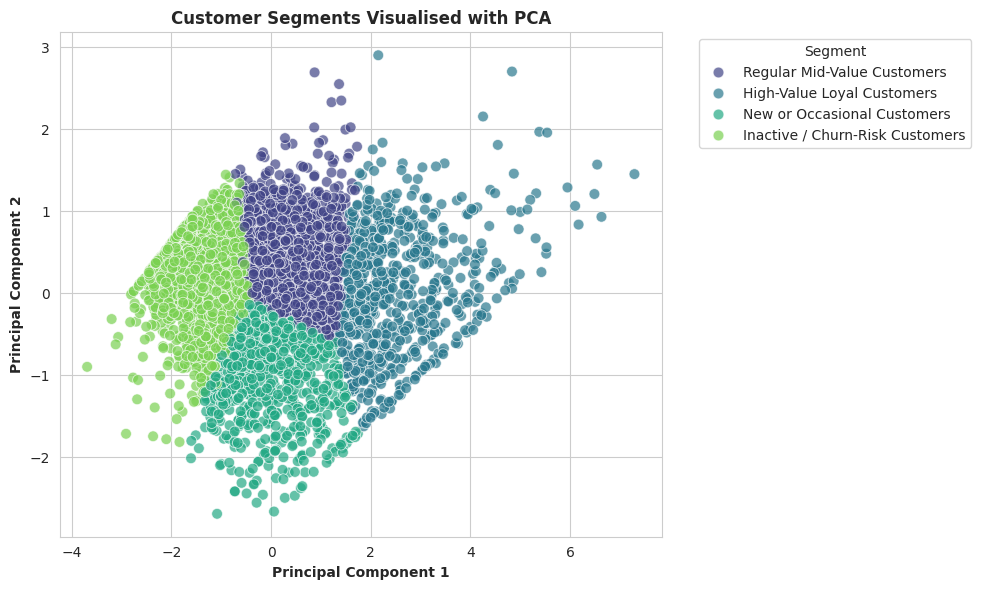

In [28]:
# Plot PCA clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Segment", palette="viridis", alpha=0.7, s=60)

plt.title("Customer Segments Visualised with PCA", fontsize=12, fontweight="bold")
plt.xlabel("Principal Component 1", fontsize=10, fontweight="bold")
plt.ylabel("Principal Component 2", fontsize=10, fontweight="bold")

plt.legend(title="Segment", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

The first two PCA components are able to explain about 93.86% of total variation and segmentation by these two components show the four clusters are well seperated with small overlapping boundaries.

### **5.4 Cluster Comparison Visualisation**

In [29]:
# Prepare cluster profile
cluster_plot = (
    rfm
    .groupby("Segment")[["Recency", "Frequency", "Monetary"]]
    .mean()
    .reset_index()
)

display(cluster_plot)

,Segment,Recency,Frequency,Monetary
0,High-Value Loyal Customers,12.171108,13.751753,8088.018331
1,Inactive / Churn-Risk Customers,181.506782,1.316893,340.998626
2,New or Occasional Customers,17.698925,2.192354,557.322616
3,Regular Mid-Value Customers,71.635506,4.078902,1801.777893


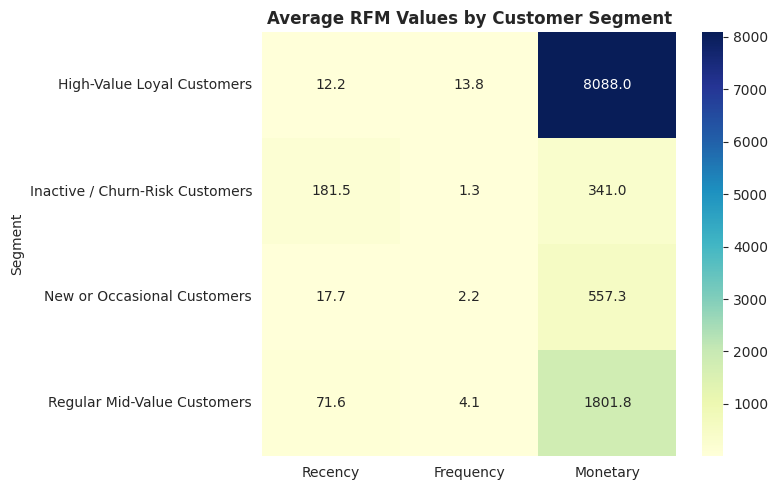

In [30]:
# Heatmap data
heatmap_data = (
    rfm
    .groupby("Segment")[["Recency", "Frequency", "Monetary"]]
    .mean()
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Average RFM Values by Customer Segment",
          fontsize=12,
          fontweight="bold")

plt.tight_layout()
plt.show()


The average values of RFM features in different customer segment shows highest recency of about 181.5 days for Inactive segment and lowest for high-value segment of about 12 days. While the frequency of spending is highest for high-value segment which also has the highest monetary spending value of about £8088 on average. The spending frequency is lowest of around 1.3 for new or occasional customer segment and monetary spending on average is lowest of around £341 for the inactive customer segment. 

## Limitations

- K-Means assumes compact, roughly spherical groups and is sensitive to scaling and outliers.
- RFM summarizes only observed transactions and does not explain customer intent or future behavior.
- Removing cancellations and missing customer identifiers is appropriate for purchase-value segmentation but excludes return behavior and anonymous demand.
- Segment labels are descriptive interpretations of cluster medians, not experimentally validated personas.

## Conclusion

The RFM analysis identifies four interpretable patterns in observed purchasing behavior. Quantitative diagnostics show that a simpler partition is stronger by silhouette score, while four clusters offer greater business interpretability. This trade-off is documented rather than presented as a uniquely correct segmentation.
